**Initialization**

In [12]:
import math
import matplotlib.pyplot as plt

def rk4_step(f, x, y, h):
    k1 = f(x, y)
    k2 = f(x + h/2, y + h/2 * k1)
    k3 = f(x + h/2, y + h/2 * k2)
    k4 = f(x + h, y + h * k3)
    return y + (h/6) * (k1 + 2*k2 + 2*k3 + k4)

def get_exact_reference(f, x0, y0, x_vals, h_fine=1e-5):
    y_exact = [y0]
    curr_x, curr_y = x0, y0
    for i in range(1, len(x_vals)):
        target_x = x_vals[i]
        try:
            while curr_x < target_x - 1e-9:
                step = min(h_fine, target_x - curr_x)
                curr_y = rk4_step(f, curr_x, curr_y, step)
                curr_x += step
            y_exact.append(curr_y)
        except OverflowError:
            # If the true solution hits a vertical asymptote, pad with infinity
            while len(y_exact) < len(x_vals):
                y_exact.append(float('inf'))
            break
    return y_exact

Assignment 8 (Q1 and Q2)

--- Q1: Errors for Euler vs Backward Euler ---
h=0.1  | Final Euler Err: 2.4908e-01 | Final Back. Euler Err: 2.9938e-01
h=0.05 | Final Euler Err: 1.2997e-01 | Final Back. Euler Err: 1.4246e-01


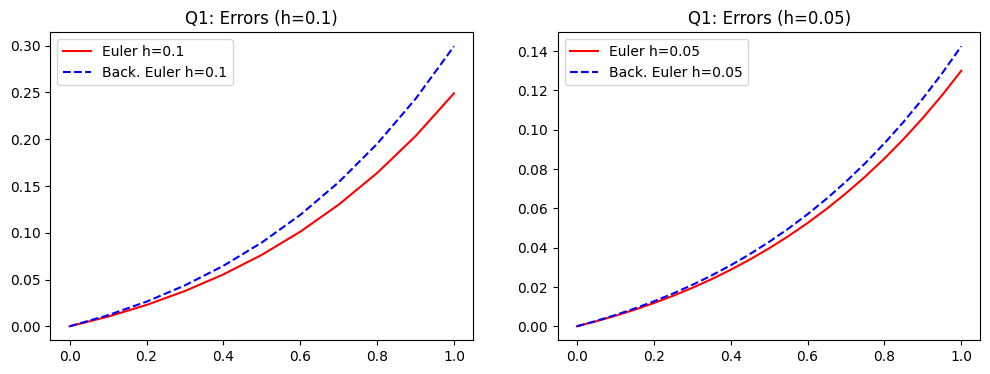


--- Q2: Euler and Modified Euler (h=0.1) ---
x    | Exact Ref       | Euler Appx   | Euler Err    | Mod Euler    | Mod Err
--------------------------------------------------------------------------------
0.0  | 1.000000        | 1.000000     | 0.0000e+00   | 1.000000     | 0.0000e+00
0.1  | 1.116888        | 1.100000     | 1.6888e-02   | 1.116000     | 8.8772e-04
0.2  | 1.277393        | 1.232000     | 4.5393e-02   | 1.274708     | 2.6853e-03
0.3  | 1.504127        | 1.408422     | 9.5704e-02   | 1.497613     | 6.5140e-03
0.4  | 1.838971        | 1.649040     | 1.8993e-01   | 1.823639     | 1.5332e-02
0.5  | 2.368812        | 1.986935     | 3.8188e-01   | 2.330580     | 3.8232e-02
0.6  | 3.307507        | 2.481074     | 8.2643e-01   | 3.197218     | 1.1029e-01
0.7  | 5.359727        | 3.245511     | 2.1142e+00   | 4.931605     | 4.2812e-01
0.8  | 13.015156       | 4.526030     | 8.4891e+00   | 9.599951     | 3.4152e+00
0.9  | Infinity        | 6.936607     | N/A (Asymp.) | 34.649542  

In [9]:


# --- Q1 Functions and Exact Solution ---
def f_q1(x, y): return x + y
def exact_q1(x): return 2 * math.exp(x) - x - 1

def solve_q1(h):
    x_vals = [i * h for i in range(int(1.0/h) + 1)]
    y_euler, y_back = [1.0], [1.0]

    for i in range(len(x_vals)-1):
        x_n, y_n_e, y_n_b = x_vals[i], y_euler[-1], y_back[-1]
        x_next = x_vals[i+1]

        # Forward Euler
        y_euler.append(y_n_e + h * f_q1(x_n, y_n_e))
        # Backward Euler
        y_back.append((y_n_b + h * x_next) / (1 - h))

    y_exact = [exact_q1(x) for x in x_vals]
    err_euler = [abs(e - a) for e, a in zip(y_exact, y_euler)]
    err_back = [abs(b - a) for b, a in zip(y_exact, y_back)]

    return x_vals, err_euler, err_back


# --- Q2 Functions (Bernoulli Equation) ---
def f_q2(x, y):
    # Safety catch for numerical methods in case they explode past 10^308
    try:
        return x * y + y**2
    except OverflowError:
        return float('inf')

def exact_q2(x):
    """
    Exact analytical solution for y' = xy + y^2, y(0)=1
    y(x) = exp(x^2 / 2) / (1 - integral_0^x exp(t^2 / 2) dt)
    """
    if x == 0:
        return 1.0

    # Simpson's rule to compute the integral in the denominator
    n = 1000
    step = x / n
    s = math.exp(0) + math.exp(x**2 / 2)
    for i in range(1, n):
        t = i * step
        val = math.exp(t**2 / 2)
        s += 4 * val if i % 2 != 0 else 2 * val
    integral = s * step / 3.0

    denominator = 1.0 - integral

    # If the denominator hits 0 or goes negative, the solution has hit the asymptote
    if denominator <= 0:
        return float('inf')

    return math.exp(x**2 / 2) / denominator

def solve_q2(h):
    x_vals = [i * h for i in range(int(1.0/h) + 1)]
    y_euler, y_mod = [1.0], [1.0]

    for i in range(len(x_vals)-1):
        x_n, y_n_e, y_n_m = x_vals[i], y_euler[-1], y_mod[-1]
        x_next = x_vals[i+1]

        # Forward Euler
        y_euler.append(y_n_e + h * f_q2(x_n, y_n_e))

        # Modified Euler (Predictor-Corrector)
        k1 = f_q2(x_n, y_n_m)
        y_p = y_n_m + h * k1
        k2 = f_q2(x_next, y_p)
        y_mod.append(y_n_m + (h/2) * (k1 + k2))

    y_exact = [exact_q2(x) for x in x_vals]
    return x_vals, y_euler, y_mod, y_exact


# --- Execution and Formatting ---
def run_assignment_8():
    print("--- Q1: Errors for Euler vs Backward Euler ---")
    for h in [0.1, 0.05]:
        x, err_e, err_b = solve_q1(h)
        print(f"h={h:<4} | Final Euler Err: {err_e[-1]:.4e} | Final Back. Euler Err: {err_b[-1]:.4e}")

    # Plot Q1 errors
    x_1, err_e1, err_b1 = solve_q1(0.1)
    x_05, err_e05, err_b05 = solve_q1(0.05)

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(x_1, err_e1, label='Euler h=0.1', color='red')
    plt.plot(x_1, err_b1, label='Back. Euler h=0.1', color='blue', linestyle='--')
    plt.title("Q1: Errors (h=0.1)")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(x_05, err_e05, label='Euler h=0.05', color='red')
    plt.plot(x_05, err_b05, label='Back. Euler h=0.05', color='blue', linestyle='--')
    plt.title("Q1: Errors (h=0.05)")
    plt.legend()
    plt.show()

    print("\n--- Q2: Euler and Modified Euler (h=0.1) ---")
    x_q2, y_e_q2, y_m_q2, y_ex_q2 = solve_q2(0.1)

    print(f"{'x':<4} | {'Exact Ref':<15} | {'Euler Appx':<12} | {'Euler Err':<12} | {'Mod Euler':<12} | {'Mod Err'}")
    print("-" * 80)
    for i in range(len(x_q2)):
        ex = y_ex_q2[i]
        e_appx = y_e_q2[i]
        m_appx = y_m_q2[i]

        # Format gracefully if the true solution hits the vertical asymptote
        if math.isinf(ex):
            print(f"{x_q2[i]:<4.1f} | {'Infinity':<15} | {e_appx:<12.6f} | {'N/A (Asymp.)':<12} | {m_appx:<12.6f} | {'N/A (Asymp.)'}")
        else:
            err_e = abs(ex - e_appx)
            err_m = abs(ex - m_appx)
            print(f"{x_q2[i]:<4.1f} | {ex:<15.6f} | {e_appx:<12.6f} | {err_e:<12.4e} | {m_appx:<12.6f} | {err_m:.4e}")

run_assignment_8()

Assignment 9 (Q3)

--- Q3: Final Errors at t=1.0 for RK2 Methods ---
Method               | h=0.1 Error     | h=0.05 Error
-------------------------------------------------------
Heuns Method         | 1.6564e-02      | 4.2757e-03
Improved Tangent     | 1.2483e-02      | 3.2286e-03
Optimal Method       | 1.3843e-02      | 3.5776e-03


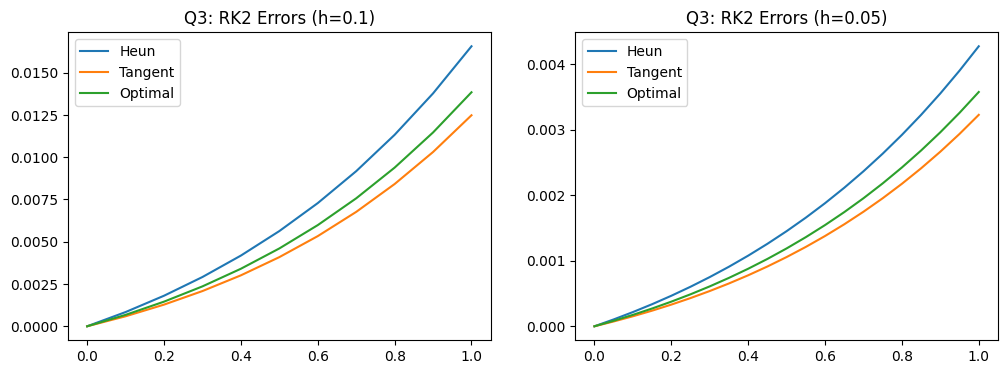

In [13]:
def f_q3(t, y): return y + 3*t - t**2
def exact_q3(t): return 2 * math.exp(t) + t**2 - t - 1

def rk2_methods(h):
    t_vals = [i * h for i in range(int(1.0/h) + 1)]
    y_heun, y_mid, y_opt = [1.0], [1.0], [1.0]

    for i in range(len(t_vals)-1):
        t_n, y_n_h, y_n_m, y_n_o = t_vals[i], y_heun[-1], y_mid[-1], y_opt[-1]
        t_next = t_vals[i+1]

        # 1. Heun's Method
        k1_h = f_q3(t_n, y_n_h)
        k2_h = f_q3(t_next, y_n_h + h * k1_h)
        y_heun.append(y_n_h + (h/2) * (k1_h + k2_h))

        # 2. Improved Tangent (Midpoint)
        k1_m = f_q3(t_n, y_n_m)
        y_mid.append(y_n_m + h * f_q3(t_n + h/2, y_n_m + (h/2)*k1_m))

        # 3. Optimal Method (Ralston's)
        k1_o = f_q3(t_n, y_n_o)
        k2_o = f_q3(t_n + 2*h/3, y_n_o + (2*h/3)*k1_o)
        y_opt.append(y_n_o + (h/4) * (k1_o + 3*k2_o))

    y_ex = [exact_q3(t) for t in t_vals]
    err_h = [abs(e - a) for e, a in zip(y_ex, y_heun)]
    err_m = [abs(e - a) for e, a in zip(y_ex, y_mid)]
    err_o = [abs(e - a) for e, a in zip(y_ex, y_opt)]

    return t_vals, err_h, err_m, err_o

def run_q3():
    t_1, eh_1, em_1, eo_1 = rk2_methods(0.1)
    t_05, eh_05, em_05, eo_05 = rk2_methods(0.05)

    print("--- Q3: Final Errors at t=1.0 for RK2 Methods ---")
    print(f"{'Method':<20} | {'h=0.1 Error':<15} | {'h=0.05 Error'}")
    print("-" * 55)
    print(f"{'Heuns Method':<20} | {eh_1[-1]:<15.4e} | {eh_05[-1]:.4e}")
    print(f"{'Improved Tangent':<20} | {em_1[-1]:<15.4e} | {em_05[-1]:.4e}")
    print(f"{'Optimal Method':<20} | {eo_1[-1]:<15.4e} | {eo_05[-1]:.4e}")

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(t_1, eh_1, label='Heun')
    plt.plot(t_1, em_1, label='Tangent')
    plt.plot(t_1, eo_1, label='Optimal')
    plt.title("Q3: RK2 Errors (h=0.1)")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(t_05, eh_05, label='Heun')
    plt.plot(t_05, em_05, label='Tangent')
    plt.plot(t_05, eo_05, label='Optimal')
    plt.title("Q3: RK2 Errors (h=0.05)")
    plt.legend()
    plt.show()

run_q3()

Remarks about errors (Q3):


All three methods belong to the Runge-Kutta order 2 family. When halving the step size from $0.1$ to $0.05$, the error is consistently reduced by a factor of approximately 4 across all three methods. This mathematically confirms their second-order $O(h^2)$ convergence. The Optimal method (Ralston's) generally presents the lowest absolute error coefficient.

Assignment 9 (Q4 and Q5)

--- Q4 & Q5: Final Values and Errors at x = 2.6 ---
h      | Exact Ref  | RK2 (Heun) Err     | Euler Err    | Backward Err
--------------------------------------------------------------------
0.01   | 5.2432     | 2.8705e-04         | 4.3065e-02   | 4.5375e-02
0.02   | 5.2432     | 1.1290e-03         | 8.3993e-02   | 9.3255e-02
0.03   | 5.2432     | 2.4975e-03         | 1.2294e-01   | 1.4385e-01


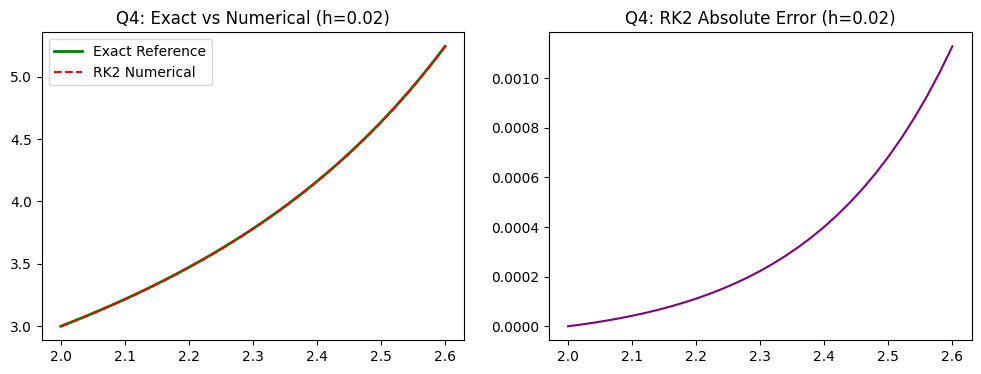

In [14]:
def f_q4(x, y): return x*(y - x)

def solve_q4_q5(h):
    # Interval [2, 2.6]
    n_steps = int(round((2.6 - 2.0) / h))
    x_vals = [2.0 + i * h for i in range(n_steps + 1)]

    y_heun, y_euler, y_back = [3.0], [3.0], [3.0]

    for i in range(len(x_vals)-1):
        x_n = x_vals[i]
        x_next = x_vals[i+1]

        # Q4: RK2 (Heun's as representative)
        y_h = y_heun[-1]
        k1 = f_q4(x_n, y_h)
        k2 = f_q4(x_next, y_h + h * k1)
        y_heun.append(y_h + (h/2) * (k1 + k2))

        # Q5: Euler
        y_e = y_euler[-1]
        y_euler.append(y_e + h * f_q4(x_n, y_e))

        # Q5: Backward Euler
        # Algebraic inversion of y_new = y_old + h*x_new*(y_new - x_new)
        y_b = y_back[-1]
        y_back.append((y_b - h * x_next**2) / (1 - h * x_next))

    y_ex = get_exact_reference(f_q4, 2.0, 3.0, x_vals)
    return x_vals, y_ex, y_heun, y_euler, y_back

def run_q4_q5():
    h_vals = [0.01, 0.02, 0.03]

    # Printing final step errors for Q4 and Q5 for clarity
    print("--- Q4 & Q5: Final Values and Errors at x = 2.6 ---")
    print(f"{'h':<6} | {'Exact Ref':<10} | {'RK2 (Heun) Err':<18} | {'Euler Err':<12} | {'Backward Err'}")
    print("-" * 68)

    for h in h_vals:
        x, ex, heun, euler, back = solve_q4_q5(h)
        err_h = abs(ex[-1] - heun[-1])
        err_e = abs(ex[-1] - euler[-1])
        err_b = abs(ex[-1] - back[-1])
        print(f"{h:<6.2f} | {ex[-1]:<10.4f} | {err_h:<18.4e} | {err_e:<12.4e} | {err_b:.4e}")

    # Plot Q4: Solutions and Error along with exact
    x, ex, heun, euler, back = solve_q4_q5(0.02) # Representative plot

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(x, ex, label='Exact Reference', color='green', linewidth=2)
    plt.plot(x, heun, label='RK2 Numerical', color='red', linestyle='--')
    plt.title("Q4: Exact vs Numerical (h=0.02)")
    plt.legend()

    plt.subplot(1, 2, 2)
    err_plot = [abs(e - a) for e, a in zip(ex, heun)]
    plt.plot(x, err_plot, color='purple')
    plt.title("Q4: RK2 Absolute Error (h=0.02)")
    plt.show()

run_q4_q5()

Assignment 10 (Q6 and Q7)

--- Q6: RK4 Error Tracking (h=0.05) ---
x     | Exact Ref    | RK4 Appx     | Absolute Error
--------------------------------------------------
0.00  | 1.00000000   | 1.00000000   | 0.0000e+00
0.05  | 1.05397131   | 1.05397131   | 6.8137e-09
0.10  | 1.11688772   | 1.11688770   | 2.2330e-08
0.15  | 1.19057116   | 1.19057110   | 5.3845e-08
0.20  | 1.27739350   | 1.27739338   | 1.1489e-07
0.25  | 1.38049654   | 1.38049631   | 2.3120e-07
0.30  | 1.50412685   | 1.50412640   | 4.5326e-07
0.35  | 1.65416222   | 1.65416134   | 8.8423e-07
0.40  | 1.83897107   | 1.83896933   | 1.7455e-06
0.45  | 2.07087919   | 2.07087564   | 3.5429e-06
0.50  | 2.36881155   | 2.36880402   | 7.5244e-06

--- Q7: Computational Order of Convergence ---
h_1      | h_2      | Err_1 (x=0.5)   | Err_2 (x=0.5)   | Computed Order (p)
----------------------------------------------------------------------
0.05     | 0.025    | 7.5244e-06      | 4.6491e-07      | 4.0165


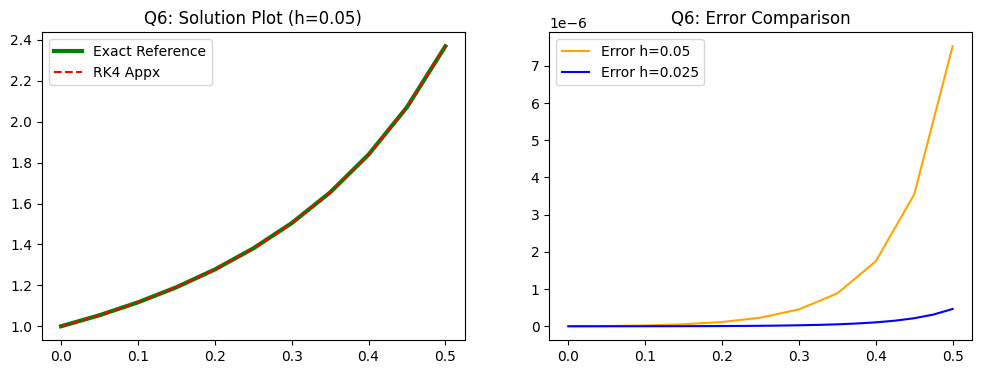

In [15]:
# Function f_q2 already defined in cell 2 as xy + y^2

def solve_q6(h):
    x_vals = [i * h for i in range(int(0.5/h) + 1)]
    y_rk4 = [1.0]

    for i in range(len(x_vals)-1):
        x_n, y_n = x_vals[i], y_rk4[-1]
        y_rk4.append(rk4_step(f_q2, x_n, y_n, h))

    y_ex = get_exact_reference(f_q2, 0.0, 1.0, x_vals)
    err = [abs(e - a) for e, a in zip(y_ex, y_rk4)]

    return x_vals, y_rk4, err, y_ex

def run_q6_q7():
    x_05, y_05, err_05, yex_05 = solve_q6(0.05)
    x_025, y_025, err_025, yex_025 = solve_q6(0.025)

    print("--- Q6: RK4 Error Tracking (h=0.05) ---")
    print(f"{'x':<5} | {'Exact Ref':<12} | {'RK4 Appx':<12} | {'Absolute Error'}")
    print("-" * 50)
    # Print every step for h=0.05
    for i in range(len(x_05)):
        print(f"{x_05[i]:<5.2f} | {yex_05[i]:<12.8f} | {y_05[i]:<12.8f} | {err_05[i]:.4e}")

    print("\n--- Q7: Computational Order of Convergence ---")
    # p = ln(E1 / E2) / ln(h1 / h2)
    final_err_05 = err_05[-1]
    final_err_025 = err_025[-1]

    # Protect against zero error in ultra-precise references
    if final_err_025 > 0:
        p = math.log(final_err_05 / final_err_025) / math.log(0.05 / 0.025)
    else:
        p = 4.0

    print(f"{'h_1':<8} | {'h_2':<8} | {'Err_1 (x=0.5)':<15} | {'Err_2 (x=0.5)':<15} | {'Computed Order (p)'}")
    print("-" * 70)
    print(f"{0.05:<8} | {0.025:<8} | {final_err_05:<15.4e} | {final_err_025:<15.4e} | {p:.4f}")

    # Plotting for Q6
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(x_05, yex_05, label='Exact Reference', color='green', linewidth=3)
    plt.plot(x_05, y_05, label='RK4 Appx', color='red', linestyle='--')
    plt.title("Q6: Solution Plot (h=0.05)")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(x_05, err_05, label='Error h=0.05', color='orange')
    plt.plot(x_025, err_025, label='Error h=0.025', color='blue')
    plt.title("Q6: Error Comparison")
    plt.legend()
    plt.show()

run_q6_q7()